In [1]:
%reset -f
'''>>>>> start CodeP2.2F25
    V.P. Carey ME249, Fall 2025

Intro to Neural Network Modeling 
Keras model for comparison with first principles model'''

#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf
#the following 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

#raw data in dictionary form x01, x02, x03, y3
my_dict = { 
    'x01' : [20., 20., 20., 20.2, 20., 20.2, 24.0, 36.],
    'x02' : [13., 14.5, 15.3, 13., 14.5, 15.3, 13., 14.4],
    'x03' : [310.8, 308.0, 306.0, 310.8, 308.0, 306.0, 310.8, 308.1],
    'y3' : [30.99, 32.2, 31.7, 30.92, 32.4, 31.4, 35.53, 46.41]
}
#normalized inputs in array
xdata = []
xdata = [[20./20.2, 13.0/14.5, 310.8/308.0], [20./20.2, 14.5/14.5, 308.0/308.0]] 
xdata.append([20./20.2, 15.3/14.5, 306.0/308.0])
xdata.append([20.2/20.2, 13.0/14.5, 310.8/308.0]) 
xdata.append([20./20.2, 14.5/14.5, 308.0/308.0]) 
xdata.append([20.2/20.2, 15.3/14.5, 306.0/308.0]) 
xdata.append([24./20.2, 13.0/14.5, 310.8/308.0]) 
xdata.append([36./20.2, 14.4/14.5, 308.1/308.0]) 

#data frame
df = pd.DataFrame(my_dict)
#devide by the median to normalize 
df.x01= df.x01/20.2
df.x02= df.x02/14.5
df.x03= df.x03/308.0
#normalize output array
df.y3= df.y3/32.401
df.head
print (df.x01, df.x02, df.x03, df.y3)

xarray= np.array(xdata)
print (xdata)
print (xarray)

0    0.990099
1    0.990099
2    0.990099
3    1.000000
4    0.990099
5    1.000000
6    1.188119
7    1.782178
Name: x01, dtype: float64 0    0.896552
1    1.000000
2    1.055172
3    0.896552
4    1.000000
5    1.055172
6    0.896552
7    0.993103
Name: x02, dtype: float64 0    1.009091
1    1.000000
2    0.993506
3    1.009091
4    1.000000
5    0.993506
6    1.009091
7    1.000325
Name: x03, dtype: float64 0    0.956452
1    0.993796
2    0.978365
3    0.954292
4    0.999969
5    0.969106
6    1.096571
7    1.432363
Name: y3, dtype: float64
[[0.9900990099009901, 0.896551724137931, 1.009090909090909], [0.9900990099009901, 1.0, 1.0], [0.9900990099009901, 1.0551724137931036, 0.9935064935064936], [1.0, 0.896551724137931, 1.009090909090909], [0.9900990099009901, 1.0, 1.0], [1.0, 1.0551724137931036, 0.9935064935064936], [1.188118811881188, 0.896551724137931, 1.009090909090909], [1.7821782178217822, 0.993103448275862, 1.0003246753246755]]
[[0.99009901 0.89655172 1.00909091]
 [0.99009901 1

In [2]:
# define model

#As seen below, we have created three dense layers each with just one neuron. 
#A dense layer is a layer in neural network that’s fully connected. 
#In other words, all the neurons in one layer are connected to all other neurons in the next layer.
#In the first layer, we need to provide the input shape, which is 3 in this case. 
#The activation function we have chosen is ReLU, which stands for rectified linear unit.

from keras import backend as K
#initialize weights with values between -0.2 and 1.2
initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=1.2)

# define three layer model with one neuron in each layer
model = keras.Sequential([
    # keras.layers.Dense(1, activation=K.elu, input_shape=[3],  kernel_initializer=initializer, name="dense_one"),
    # keras.layers.Dense(1, activation=K.elu,  kernel_initializer=initializer, name="dense_two"),
    # keras.layers.Dense(1, activation=K.elu,  kernel_initializer=initializer, name="dense_three")
    keras.layers.Dense(1, activation='elu', input_shape=[3],  kernel_initializer=initializer, name="dense_one"),
    keras.layers.Dense(1, activation='elu',  kernel_initializer=initializer, name="dense_two"),
    keras.layers.Dense(1, activation='elu',  kernel_initializer=initializer, name="dense_three")
  ])
model.summary()

# #set original starting values to those used in first principles model
# w01n =  1.23 
# w02n =  0.40 
# w03n =  0.70
# b1n =  -0.15
# w12n =  0.72
# b2n =  -0.12
# w23n =  0.7
# b3n =  0.01

#set starting values to those used in first principles model with 20% higher than original value
w01n =  1.23*1.2
w02n =  0.40*1.2
w03n =  0.70*1.2
b1n =  -0.15*1.2
w12n =  0.72*1.2
b2n =  -0.12*1.2
w23n =  0.7*1.2
b3n =  0.01*1.2


weights0 =  [[ w01n], [w02n], [ w03n]]
w0array= np.array(weights0)
print(np.shape(w0array))
bias0 = [b1n]
bias0array= np.array(bias0)
L0=[]
L0.append(w0array)
L0.append(bias0array)
model.layers[0].set_weights(L0) 

weights1 =  [[ w12n]]
w1array= np.array(weights1)
print(np.shape(w1array))
bias1 = [b2n]
bias1array= np.array(bias1)
L1=[]
L1.append(w1array)
L1.append(bias1array)
model.layers[1].set_weights(L1)

weights2 =  [[ w23n]]
w2array= np.array(weights2)
print(np.shape(w2array))
bias2 = [b3n]
bias2array= np.array(bias2)
L2=[]
L2.append(w2array)
L2.append(bias2array)
model.layers[2].set_weights(L2)




/global/home/users/melius/.conda/envs/my_kernel/lib/python3.11/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-10-28 16:06:52.274945: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_one (Dense)               │ (None, 1)              │             4 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_two (Dense)               │ (None, 1)              │             2 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_three (Dense)             │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

(3, 1)
(1, 1)
(1, 1)


In [24]:
#We’re using RMSprop as our optimizer here. RMSprop stands for Root Mean Square Propagation. 
#It’s one of the most popular gradient descent optimization algorithms for deep learning networks. 
#RMSprop is an optimizer that’s reliable and fast.
#We’re compiling the mode using the model.compile function. The loss function used here 
#is mean absolute error. After the compilation of the model, we’ll use the fit method with 100 epochs.

#Running model.fit successive times extends the calculation to addtional epochs.

# rms = keras.optimizers.RMSprop(0.0035)
rms = keras.optimizers.RMSprop(0.030)
model.compile(loss='mean_absolute_error',optimizer=rms)


In [25]:
#After the compilation of the model, we’ll use the fit method with 500 epochs.
#I started with epochs value of 100 and then tested the model after training. 
#The prediction was not that good. Then I modified the number of epochs to 200 and tested the model again. 
#Accuracy had improved slightly, but figured I’d give it one more try. Finally, at 500 epochs 
#I found acceptable prediction accuracy.

#The fit method takes three parameters; namely, x, y, and number of epochs. 
#During model training, if all the batches of data are seen by the model once, 
#we say that one epoch has been completed.

# Add an early stopping callback
es = tf.keras.callbacks.EarlyStopping(
    monitor='loss', 
    mode='min', 
    patience = 80, 
    restore_best_weights = True, 
    verbose=1)
# Add a checkpoint where loss is minimum, and save that model
# mc = tf.keras.callbacks.ModelCheckpoint('best_model.SB', monitor='loss', 
mc = tf.keras.callbacks.ModelCheckpoint('best_model.keras', monitor='loss', 
                     mode='min',  verbose=1, save_best_only=True)

historyData = model.fit(xarray,df.y3,epochs=400,callbacks=[es])

loss_hist = historyData.history['loss']
#The above line will return a dictionary, access it's info like this:
best_epoch = np.argmin(historyData.history['loss']) + 1
print ('best epoch = ', best_epoch)
print('smallest loss =', np.min(loss_hist))

Epoch 1/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - loss: 0.8587
Epoch 2/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0604
Epoch 3/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.3628
Epoch 4/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0596
Epoch 5/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.2308
Epoch 6/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.1426
Epoch 7/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.1629
Epoch 8/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.1538
Epoch 9/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1171
Epoch 10/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1673
Epoch 11/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0819
Epoch 12/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.1814
Epoch 13/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0527
Epoch 14/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1957
Epoch 15/400
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0336
Epoch 16/400
1/1 ━

In [26]:
from __future__ import print_function
#For results of training network:

#keras.layer.get_weights() function retrieves weight values
first_layer_weights = model.layers[0].get_weights()[0]
w01 = first_layer_weights[0][0]
w02 = first_layer_weights[1][0]
w03 = first_layer_weights[2][0]
first_layer_bias  = model.layers[0].get_weights()[1]
b1 = first_layer_bias
second_layer_weights = model.layers[1].get_weights()[0]
w12 = second_layer_weights[0][0]
second_layer_bias  = model.layers[1].get_weights()[1]
b2 = second_layer_bias
third_layer_weights = model.layers[2].get_weights()[0]
w23 = third_layer_weights[0][0]
third_layer_bias  = model.layers[2].get_weights()[1]
b3 = third_layer_bias

#print weights and biases
print (first_layer_weights)
print ('w01 = ', w01, 'w02 = ', w02, 'w03 = ', w03)
print (first_layer_bias)
print ('b1 = ', b1)
print (second_layer_weights)
print ('w12 = ', w12)
print (second_layer_bias)
print ('b2 = ', b2)
print (third_layer_weights)
print ('w23 = ', w23)
print (third_layer_bias)
print ('b3 = ', b3)

#use model.predict() function to print model predictions for data conditions
xarray= np.array(xdata)
print ('x01/20.2,  x02/14.5,   x03/308.0,  y3/32.4,  a3:')
test = []
for i in range(0,8): 
    test = [[xarray[i][0], xarray[i][1], xarray[i][2]]]
    testarray = np.array(test)
    a3 = model.predict(testarray)
    print (xarray[i][0], xarray[i][1], xarray[i][2], df.y3[i], a3)
print('  ')
print ('x01,  x02,   x03,  y3,  a3*32.4:')
for i in range(0,8): 
    test = [[xarray[i][0], xarray[i][1], xarray[i][2]]]
    testarray = np.array(test)
    a3 = model.predict(testarray)
    print (xarray[i][0]*20.2, xarray[i][1]*14.5, xarray[i][2]*308.0, df.y3[i]*32.4, a3*32.4)

[[1.3305638 ]
 [0.36953682]
 [0.72552633]]
w01 =  1.3305638 w02 =  0.36953682 w03 =  0.72552633
[-0.29425886]
b1 =  [-0.29425886]
[[0.69765025]]
w12 =  0.69765025
[-0.14296538]
b2 =  [-0.14296538]
[[0.5929408]]
w23 =  0.5929408
[0.14315481]
b3 =  [0.14315481]
x01/20.2,  x02/14.5,   x03/308.0,  y3/32.4,  a3:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
0.9900990099009901 0.896551724137931 1.009090909090909 0.9564519613592172 [[0.92152303]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
0.9900990099009901 1.0 1.0 0.9937964877627233 [[0.9346082]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
0.9900990099009901 1.0551724137931036 0.9935064935064936 0.9783648652819357 [[0.9410933]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1.0 0.896551724137931 1.009090909090909 0.954291534211907 [[0.9269727]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
0.9900990099009901 1.0 1.0 0.9999691367550383 [[0.9346082]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1.0 1.0551724137931036 0.9935064935064936 0.9691058917934631 [[0.9465428]]
1/1 ━━━━━━━━━━━━━

FIRST PRINCIPLES MODEL
Index  Actual (°C)     Predicted (°C)     Error (°C)      Error (%) 
------------------------------------------------------------------------------------------
0      30.9700         31.1877            0.2177          0.70      %
1      32.3000         31.7385            -0.5615         -1.74     %
2      31.5000         32.0139            0.5139          1.63      %
3      30.9100         31.3834            0.4734          1.53      %
4      32.5000         31.7385            -0.7615         -2.34     %
5      31.4000         32.0139            0.6139          1.96      %
6      35.5900         35.1022            -0.4878         -1.37     %
7      46.4100         47.3567            0.9467          2.04      %
------------------------------------------------------------------------------------------

KERAS MODEL
Index  Actual (°C)     Predicted (°C)     Error (°C)      Error (%) 
------------------------------------------------------------------------------------

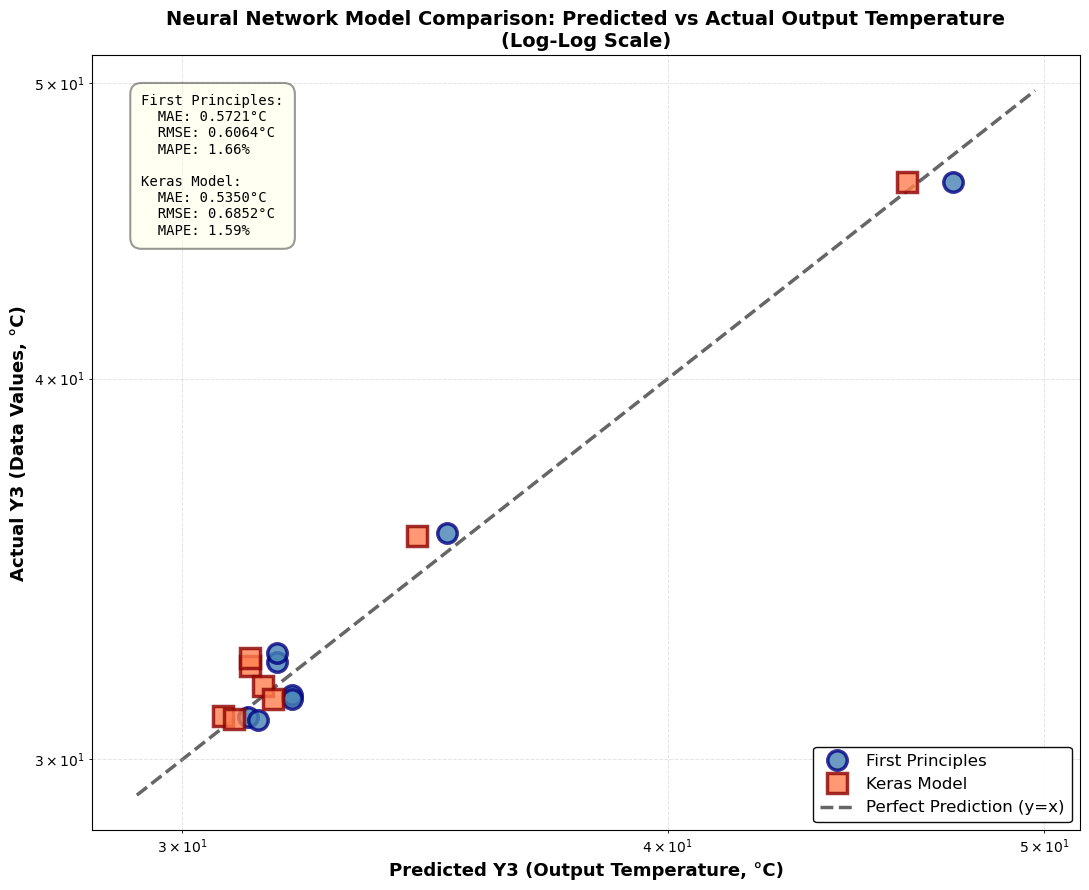

In [20]:
"""
Single Log-Log Plot: Neural Network Predictions vs Actual Values
First Principles vs Keras Model - Using Actual Data

ME249 - Spray Cooling System Neural Network Project
V.P. Carey, Fall 2025
"""

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# ACTUAL DATA FROM MODELS
# ============================================================

# First Principles Model Data
# Format: Tdbin, Twbin, qdot, Tdbout (actual), ypredicted
fp_data = [
    [20.0, 13.0, 310.8, 30.97, 31.187674466338166],
    [20.0, 14.5, 308.0, 32.3, 31.738492841534573],
    [20.0, 15.3, 306.0, 31.5, 32.01389557670518],
    [20.2, 13.0, 310.8, 30.91, 31.383400627268312],
    [20.0, 14.5, 308.0, 32.5, 31.738492841534573],
    [20.0, 15.3, 306.0, 31.4, 32.01389557670518],
    [24.0, 13.0, 310.8, 35.59, 35.1021976849411],
    [36.0, 14.4, 308.0, 46.41, 47.35672275614189]
]

# Keras Model Data
# Format: actual (y3), predicted (a3*32.4)
keras_data = [
    [30.989043548038634, 30.738674],
    [32.19900620351223, 31.221966],
    [31.699021635134713, 31.461542],
    [30.919045708465788, 30.924967],
    [32.39900003086324, 31.221966],
    [31.3990308941082, 31.647833],
    [35.52890342890652, 34.464474],
    [46.40856763680132, 46.089832]
]

# Extract data
fp_actual = [row[3] for row in fp_data]
fp_predicted = [row[4] for row in fp_data]

keras_actual = [row[0] for row in keras_data]
keras_predicted = [row[1] for row in keras_data]

# ============================================================
# PRINT DATA TABLE
# ============================================================

print("=" * 90)
print("FIRST PRINCIPLES MODEL")
print("=" * 90)
print(f"{'Index':<6} {'Actual (°C)':<15} {'Predicted (°C)':<18} {'Error (°C)':<15} {'Error (%)':<10}")
print("-" * 90)

fp_errors = []
for i in range(len(fp_actual)):
    error = fp_predicted[i] - fp_actual[i]
    error_pct = (error / fp_actual[i]) * 100
    fp_errors.append(error)
    print(f"{i:<6} {fp_actual[i]:<15.4f} {fp_predicted[i]:<18.4f} {error:<15.4f} {error_pct:<10.2f}%")

print("-" * 90)

print("\n" + "=" * 90)
print("KERAS MODEL")
print("=" * 90)
print(f"{'Index':<6} {'Actual (°C)':<15} {'Predicted (°C)':<18} {'Error (°C)':<15} {'Error (%)':<10}")
print("-" * 90)

keras_errors = []
for i in range(len(keras_actual)):
    error = keras_predicted[i] - keras_actual[i]
    error_pct = (error / keras_actual[i]) * 100
    keras_errors.append(error)
    print(f"{i:<6} {keras_actual[i]:<15.4f} {keras_predicted[i]:<18.4f} {error:<15.4f} {error_pct:<10.2f}%")

print("-" * 90)

# ============================================================
# CREATE SINGLE LOG-LOG PLOT
# ============================================================

plt.figure(figsize=(11, 9))

# Plot both models on same plot
plt.loglog(fp_predicted, fp_actual, 'o', color='steelblue', 
           markersize=14, label='First Principles', alpha=0.8, 
           markeredgecolor='navy', markeredgewidth=2.5)

plt.loglog(keras_predicted, keras_actual, 's', color='coral', 
           markersize=14, label='Keras Model', alpha=0.8, 
           markeredgecolor='darkred', markeredgewidth=2.5)

# Perfect prediction line (y = x)
min_val = min(min(fp_predicted), min(keras_predicted), min(fp_actual), min(keras_actual)) * 0.95
max_val = max(max(fp_predicted), max(keras_predicted), max(fp_actual), max(keras_actual)) * 1.05
plt.loglog([min_val, max_val], [min_val, max_val], 'k--', linewidth=2.5, 
           alpha=0.6, label='Perfect Prediction (y=x)', zorder=1)

# Labels and title
plt.xlabel('Predicted Y3 (Output Temperature, °C)', fontsize=13, fontweight='bold')
plt.ylabel('Actual Y3 (Data Values, °C)', fontsize=13, fontweight='bold')
plt.title('Neural Network Model Comparison: Predicted vs Actual Output Temperature\n(Log-Log Scale)', 
          fontsize=14, fontweight='bold')

# Grid and legend
plt.grid(True, which='both', alpha=0.35, linestyle='--', linewidth=0.7)
plt.legend(fontsize=12, loc='best', framealpha=0.95, edgecolor='black', fancybox=True)

# Calculate statistics for both models
fp_mae = np.mean(np.abs(np.array(fp_errors)))
fp_rmse = np.sqrt(np.mean(np.array(fp_errors)**2))
fp_mape = np.mean(np.abs(np.array(fp_errors) / np.array(fp_actual))) * 100

keras_mae = np.mean(np.abs(np.array(keras_errors)))
keras_rmse = np.sqrt(np.mean(np.array(keras_errors)**2))
keras_mape = np.mean(np.abs(np.array(keras_errors) / np.array(keras_actual))) * 100

# Display statistics box
stats_text = (f'First Principles:\n'
              f'  MAE: {fp_mae:.4f}°C\n'
              f'  RMSE: {fp_rmse:.4f}°C\n'
              f'  MAPE: {fp_mape:.2f}%\n\n'
              f'Keras Model:\n'
              f'  MAE: {keras_mae:.4f}°C\n'
              f'  RMSE: {keras_rmse:.4f}°C\n'
              f'  MAPE: {keras_mape:.2f}%')

plt.text(0.05, 0.95, stats_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='top', family='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.4, 
                   edgecolor='black', linewidth=1.5, pad=0.8))

plt.tight_layout()
plt.savefig('loglog_plot_actual_data.png', dpi=300, bbox_inches='tight')
print("\n" + "=" * 90)
print("Plot saved to: loglog_plot_actual_data.png")
print("=" * 90)

# ============================================================
# DETAILED STATISTICS
# ============================================================

print("\n" + "=" * 90)
print("DETAILED PERFORMANCE STATISTICS")
print("=" * 90)

print(f"\n{'Metric':<40} {'First Principles':<25} {'Keras Model':<25}")
print("-" * 90)

print(f"{'Mean Absolute Error (MAE)':<40} {fp_mae:<25.6f}°C {keras_mae:<25.6f}°C")
print(f"{'Root Mean Squared Error (RMSE)':<40} {fp_rmse:<25.6f}°C {keras_rmse:<25.6f}°C")
print(f"{'Mean Absolute Percentage Error (MAPE)':<40} {fp_mape:<25.4f}% {keras_mape:<25.4f}%")

print(f"\n{'Min Prediction':<40} {min(fp_predicted):<25.4f}°C {min(keras_predicted):<25.4f}°C")
print(f"{'Max Prediction':<40} {max(fp_predicted):<25.4f}°C {max(keras_predicted):<25.4f}°C")
print(f"{'Mean Prediction':<40} {np.mean(fp_predicted):<25.4f}°C {np.mean(keras_predicted):<25.4f}°C")
print(f"{'Std Dev Prediction':<40} {np.std(fp_predicted):<25.4f}°C {np.std(keras_predicted):<25.4f}°C")

print(f"\n{'Min Actual Data':<40} {min(fp_actual):<25.4f}°C {min(keras_actual):<25.4f}°C")
print(f"{'Max Actual Data':<40} {max(fp_actual):<25.4f}°C {max(keras_actual):<25.4f}°C")
print(f"{'Mean Actual Data':<40} {np.mean(fp_actual):<25.4f}°C {np.mean(keras_actual):<25.4f}°C")
print(f"{'Std Dev Actual Data':<40} {np.std(fp_actual):<25.4f}°C {np.std(keras_actual):<25.4f}°C")

print("\n" + "=" * 90)

# Calculate R-squared (coefficient of determination)
fp_ss_res = np.sum(np.array(fp_errors)**2)
fp_ss_tot = np.sum((np.array(fp_actual) - np.mean(fp_actual))**2)
fp_r_squared = 1 - (fp_ss_res / fp_ss_tot)

keras_ss_res = np.sum(np.array(keras_errors)**2)
keras_ss_tot = np.sum((np.array(keras_actual) - np.mean(keras_actual))**2)
keras_r_squared = 1 - (keras_ss_res / keras_ss_tot)

print(f"\nR-squared (R²) - Goodness of Fit:")
print(f"  First Principles: {fp_r_squared:.6f}")
print(f"  Keras Model:      {keras_r_squared:.6f}")

print("\n" + "=" * 90)

plt.show()